# Pipeline Data + Model LSTM (BTC, ETH, SOL, multi-horizon)

**Bagian A — Pipeline Data**: ekstraksi, konversi, dan preprocessing data BTC/ETH/SOL dari Indodax dan Binance.

**Bagian B — Model LSTM**: 5 model terpisah per aset (h = 1, 3, 7, 14, 30 hari), evaluasi
(MAE, RMSE, MAPE, R2), dan prediksi 5 titik ke depan per horizon.

**Bagian C — Integrasi Markowitz**: konversi prediksi harga ke expected return, matriks
covariance dari data historis, dan optimasi bobot portofolio (maksimasi Sharpe Ratio,
batas minimum 20% per aset).

**v2 (seeded):** setiap model dilatih `len(SEEDS)` kali dengan seed berbeda. Tabel perbandingan di Bagian B tetap memakai run kanonik (`rep == 0`) supaya alur forecast & Markowitz tidak berubah; ringkasan mean ± std + MASE ada di sel terakhir.

**v3 (1500 baris):** salinan dari v2 (seeded), hanya dataset yang berubah (1500 baris/aset, 2022-10-04 s/d 2026-11-11; dibaca dari dataset yang diunggah, opsi `DATA_SOURCE = "live"` tersedia). Model, loss, window, seed identik dengan v2. `END_DATE` dipatok 2026-11-11 agar fetch live tidak ikut memuat candle hari ini yang belum selesai dan hasilnya reproducible. Karena split memakai rasio 70/15/15, jendela uji ikut bergeser (test 2026-03-06..2026-10-12, 162 titik evaluasi; 87 titik lama termuat di dalamnya), jadi perbandingan v2 vs v3 **wajib memakai MASE**, bukan MAPE mentah.

In [1]:
!pip install ccxt scikit-learn joblib tensorflow matplotlib -q

In [2]:
import os
import ccxt
import joblib
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv1D, Add, Activation, GlobalAveragePooling1D

In [3]:
ASSETS = ["BTC", "ETH", "SOL"]
# Tiap horizon punya model + target_scaler sendiri (3 aset x 5 horizon x 2 algoritma = 30 model).
HORIZONS = [1, 3, 7, 14, 30]
LIMIT = 1500                # v3: 1500 baris per seri (dipotong dari dataset terunggah)
EXPECTED_ROWS = 1500        # target; guard memakai N_ROWS yang benar-benar terbaca

# Tanggal akhir data DIPATOK. Tanpa ini, data "hari ini" ikut masuk padahal candle
# harian belum selesai (Close = harga berjalan, Volume parsial), dan jendela uji
# bergeser tiap hari. 2026-11-11 = akhir data v2, jadi jendela uji sebanding.
END_DATE = "2026-11-11"

# Sumber data:
#   "kaggle_input" -> baca CSV yang sudah diunggah (dataset beku; ini yang dipakai skripsi)
#   "live"         -> fetch dari API Indodax + Binance (butuh api.binance.com)
DATA_SOURCE = "kaggle_input"

RAW_DIR, MERGED_DIR, PROCESSED_DIR, SCALER_DIR = "data/raw", "data/merged", "data/processed", "models"
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15

FEATURE_COLS = [
    "Open_indodax", "High_indodax", "Low_indodax", "Close_indodax", "Volume_indodax",
    "Open_binance", "High_binance", "Low_binance", "Close_binance", "Volume_binance",
]

WINDOW_SIZE = 60
EPOCHS = 100
BATCH_SIZE = 16
PATIENCE = 15

for d in [RAW_DIR, MERGED_DIR, PROCESSED_DIR, SCALER_DIR]:
    os.makedirs(d, exist_ok=True)

# ============================ REPRODUCIBILITY ============================
import random
import tensorflow as tf

# 1 seed  -> hasil reproducible, tapi tetap cuma 1 sampel (tidak bisa diklaim "lebih baik").
# 3 seed  -> bisa lapor mean +- std, syarat untuk mengklaim LSTM vs TCN berbeda.
SEEDS = [42, 123, 2024]

def set_seed(seed):
    """Kunci python, numpy, dan tensorflow/keras sebelum model dibuat."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    # Opsional, lebih lambat tapi bit-identik di CPU:
    # tf.config.experimental.enable_op_determinism()

def seed_for(asset, model, horizon, rep):
    """Seed deterministik per (aset, algoritma, horizon, repeat). Jangan pakai hash()."""
    idx = ASSETS.index(asset) * 10 + HORIZONS.index(horizon)
    idx += 0 if model == "LSTM" else 100
    return 1000 * rep + idx

ALL_RUNS = []      # semua hasil training, satu baris per seed
PRED_RECORDS = []  # prediksi per titik (aset, model, h, seed, tanggal, y_true, y_pred)


## Bagian A — Pipeline Data

### Fungsi bantu

In [4]:
def fetch_ohlcv(exchange, symbol, limit=LIMIT, timeframe="1d", page_limit=1000, end=END_DATE):
    """Ambil `limit` candle harian terakhir yang berakhir di tanggal `end`.

    Pagination otomatis: ccxt membatasi ~1000 candle per request, jadi 1500 baris
    butuh 2 request. Diambil limit+30 lalu dipotong tail(limit) supaya aman kalau
    ada tanggal yang tidak tersedia di bursa.
    """
    ms_per_candle = exchange.parse_timeframe(timeframe) * 1000
    end_ms = int(pd.Timestamp(end, tz="UTC").timestamp() * 1000)

    since = end_ms - (limit + 29) * ms_per_candle
    rows = []
    while True:
        batch = exchange.fetch_ohlcv(symbol, timeframe, since=since, limit=page_limit)
        if not batch:
            break
        rows += batch
        next_since = batch[-1][0] + ms_per_candle
        if next_since <= since:      # tidak maju -> hentikan, cegah loop tanpa akhir
            break
        since = next_since
        if len(batch) < page_limit:  # sudah sampai data terbaru
            break

    df = pd.DataFrame(rows, columns=["Timestamp", "Open", "High", "Low", "Close", "Volume"])
    df = df.drop_duplicates(subset="Timestamp").sort_values("Timestamp")
    df["Tanggal"] = pd.to_datetime(df["Timestamp"], unit="ms")
    df = df[df["Tanggal"] <= pd.Timestamp(end)].tail(limit).reset_index(drop=True)
    return df[["Tanggal", "Open", "High", "Low", "Close", "Volume"]]


# how="left": kurs USDT/IDR yang hilang menjadi NaN.
def convert_binance_to_idr(df_binance, df_kurs):
    """Konversi harga/volume USDT -> IDR memakai kurs USDT/IDR harian."""
    df = df_binance.merge(df_kurs[["Tanggal", "Close"]].rename(columns={"Close": "Kurs_USDT_IDR"}), on="Tanggal", how="left")
    for col in ["Open", "High", "Low", "Close"]:
        df[f"{col}_IDR"] = df[col] * df["Kurs_USDT_IDR"]
    df["Volume_IDR"] = df["Volume"] * df["Close_IDR"]
    df_idr = df[["Tanggal", "Open_IDR", "High_IDR", "Low_IDR", "Close_IDR", "Volume_IDR"]].copy()
    df_idr.columns = ["Tanggal", "Open", "High", "Low", "Close", "Volume"]
    df_idr["Tanggal"] = pd.to_datetime(df_idr["Tanggal"])
    return df_idr


# Target_h dihitung SEBELUM split; untuk h>1 target di akhir train bisa berasal dari periode val/test.
def add_targets(df, close_col="Close_indodax", horizons=HORIZONS):
    """Tambah Target_hd = Close t+h, buang ekor tanpa target."""
    df = df.sort_values("Tanggal").reset_index(drop=True)
    for h in horizons:
        df[f"Target_{h}d"] = df[close_col].shift(-h)
    return df.iloc[:-max(horizons)].reset_index(drop=True)


def chronological_split(df, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO):
    """Bagi berurutan waktu jadi train, val, test."""
    train_end = int(len(df) * train_ratio)
    val_end = train_end + int(len(df) * val_ratio)
    return df.iloc[:train_end].reset_index(drop=True), df.iloc[train_end:val_end].reset_index(drop=True), df.iloc[val_end:].reset_index(drop=True)


# Scaler fit HANYA di train.
def fit_scale(train, val, test, feature_cols=FEATURE_COLS):
    """Fit MinMaxScaler hanya dari train (kolom fitur saja), lalu transform ketiganya.
    Target_hd SENGAJA tidak ikut di-scale di sini -- scaling target dilakukan terpisah
    per horizon di train_lstm_for_horizon(), supaya tiap horizon punya skala targetnya sendiri."""
    scaler = MinMaxScaler(feature_range=(0, 1)).fit(train[feature_cols])
    for split in (train, val, test):
        split[feature_cols] = scaler.transform(split[feature_cols])
    return train, val, test, scaler

### Tahap 1–2: Ekstraksi, Konversi, Penggabungan

In [5]:
# --- Ekstraksi data: dataset terunggah (default) atau fetch API ---
# DATA_SOURCE diatur di sel config. Dataset beku lebih baik untuk skripsi: angkanya
# tidak berubah hanya karena notebook dijalankan di hari yang berbeda.
raw_data = {}

if DATA_SOURCE == "kaggle_input":
    found = glob.glob("/kaggle/input/**/USDT_IDR.csv", recursive=True)
    assert found, ("USDT_IDR.csv tidak ditemukan di /kaggle/input. "
                   "Attach dataset 1500 baris, atau set DATA_SOURCE = 'live'.")
    # sorted() supaya deterministik kalau ada lebih dari satu dataset ter-attach;
    # folder yang dipakai dicetak, jadi kelihatan mana yang benar-benar dibaca.
    src_dir = os.path.dirname(sorted(found)[0])
    print(f"Sumber : {src_dir} (dataset terunggah)")

    names = ["USDT_IDR"] + [f"indodax_{a}" for a in ASSETS] + [f"binance_{a}" for a in ASSETS]
    for name in names:
        df = pd.read_csv(os.path.join(src_dir, f"{name}.csv"), parse_dates=["Tanggal"])
        print(f"OK  : {name:16s} {len(df):5d} baris | "
              f"{df['Tanggal'].min().date()} s/d {df['Tanggal'].max().date()}")
        raw_data[name] = df

else:
    # Diadaptasi dari pipeline_data_dan_lstm_btc_(4).ipynb (fetch_ohlcv dengan pagination).
    indodax = ccxt.indodax({"enableRateLimit": True})
    binance = ccxt.binance({"enableRateLimit": True})
    failures = []

    def safe_fetch(exchange, symbol, key):
        try:
            raw_data[key] = fetch_ohlcv(exchange, symbol)
            print(f"OK  : {symbol:10s} dari {exchange.id:8s} {len(raw_data[key]):5d} baris")
        except Exception as e:
            failures.append(f"{exchange.id} {symbol}: {e}")
            print(f"GAGAL: {symbol:10s} dari {exchange.id:8s} -> {e}")

    safe_fetch(indodax, "USDT/IDR", "USDT_IDR")
    for asset in ASSETS:
        safe_fetch(indodax, f"{asset}/IDR", f"indodax_{asset}")
    for asset in ASSETS:
        safe_fetch(binance, f"{asset}/USDT", f"binance_{asset}")

    # Gagal diam-diam = aset hilang dari hasil. Lebih baik berhenti di sini.
    assert not failures, "Fetch gagal, data tidak lengkap:\n" + "\n".join(failures)

# --- Normalisasi: buang candle setelah END_DATE, ambil LIMIT baris terakhir ---
# Tanpa ini, dataset yang diunduh "hari ini" memuat candle hari ini yang belum selesai
# (Close = harga berjalan, Volume masih parsial) dan jendela uji bergeser tiap hari.
for name, df in list(raw_data.items()):
    df = df.sort_values("Tanggal").reset_index(drop=True)
    raw_data[name] = df[df["Tanggal"] <= pd.Timestamp(END_DATE)].tail(LIMIT).reset_index(drop=True)

# Semua seri WAJIB punya tanggal identik. Kalau tidak, inner join memotong baris
# dan jumlah data per aset jadi berbeda tanpa error.
ref_idx = raw_data["USDT_IDR"]["Tanggal"]
for name, df in raw_data.items():
    assert df["Tanggal"].equals(ref_idx), (
        f"{name}: tanggal tidak identik dengan USDT_IDR ({len(df)} vs {len(ref_idx)} baris). "
        "Inner join akan memotong data -> split bergeser.")

N_ROWS = len(ref_idx)
print(f"\n{N_ROWS} baris per seri | {ref_idx.iloc[0].date()} s/d {ref_idx.iloc[-1].date()}")

assert N_ROWS >= EXPECTED_ROWS - 30, (
    f"Terbaca hanya {N_ROWS} baris (target {EXPECTED_ROWS}). Dataset yang ter-attach "
    "kemungkinan masih versi 1000 baris, atau END_DATE terlalu awal.")
if N_ROWS != EXPECTED_ROWS:
    print(f"[PERINGATAN] target {EXPECTED_ROWS} baris, terbaca {N_ROWS} "
          f"(kemungkinan data diunduh setelah {END_DATE}). Split memakai {N_ROWS} baris; "
          "nilai sebenarnya dicatat di kolom dataset_rows.")

for name, df in raw_data.items():
    df.to_csv(os.path.join(RAW_DIR, f"{name}.csv"), index=False)
print(f"Tersimpan ke : {RAW_DIR}/")


Sumber : /kaggle/input/datasets/miguelvalentino/raw-binance-indodax/raw (dataset terunggah)
OK  : USDT_IDR          1500 baris | 2022-10-04 s/d 2026-11-11
OK  : indodax_BTC       1500 baris | 2022-10-04 s/d 2026-11-11
OK  : indodax_ETH       1500 baris | 2022-10-04 s/d 2026-11-11
OK  : indodax_SOL       1500 baris | 2022-10-04 s/d 2026-11-11
OK  : binance_BTC       1500 baris | 2022-10-04 s/d 2026-11-11
OK  : binance_ETH       1500 baris | 2022-10-04 s/d 2026-11-11
OK  : binance_SOL       1500 baris | 2022-10-04 s/d 2026-11-11

1500 baris per seri | 2022-10-04 s/d 2026-11-11
Tersimpan ke : data/raw/


In [6]:
# Merge Indodax + Binance (Binance dikonversi ke IDR dulu)
# Inner join per tanggal: baris yang tidak ada di salah satu bursa hilang.
merged_data = {}
for asset in ASSETS:
    try:
        df_merged = pd.merge(raw_data[f"indodax_{asset}"], convert_binance_to_idr(raw_data[f"binance_{asset}"], raw_data["USDT_IDR"]), on="Tanggal", how="inner", suffixes=("_indodax", "_binance"))
        merged_data[asset] = df_merged
        # Guard: kalau inner join memotong baris, split bergeser TANPA error.
        assert len(df_merged) == N_ROWS, (
            f"{asset}: merged {len(df_merged)} baris, seharusnya {N_ROWS} "
            "(tanggal antar bursa tidak cocok).")
        path = os.path.join(MERGED_DIR, f"{asset}_merged.csv")
        df_merged.to_csv(path, index=False)
        print(f"Tersimpan: {path} ({len(df_merged)} baris setelah inner join tanggal)")
    except KeyError as e:
        print(f"[PERINGATAN] Lewati {asset}, data mentah belum lengkap: {e}")

merged_data["BTC"].tail()

Tersimpan: data/merged/BTC_merged.csv (1500 baris setelah inner join tanggal)
Tersimpan: data/merged/ETH_merged.csv (1500 baris setelah inner join tanggal)
Tersimpan: data/merged/SOL_merged.csv (1500 baris setelah inner join tanggal)


,Tanggal,Open_indodax,High_indodax,Low_indodax,Close_indodax,Volume_indodax,Open_binance,High_binance,Low_binance,Close_binance,Volume_binance
1495,2026-11-07,1.372970e+09,1.376808e+09,1.367430e+09,1.370006e+09,9.858261,1.369667e+09,1.376999e+09,1.364738e+09,1.370093e+09,7.146275e+12
1496,2026-11-08,1.370006e+09,1.375000e+09,1.334026e+09,1.351998e+09,16.450404,1.372065e+09,1.378077e+09,1.329428e+09,1.353688e+09,1.280272e+13
1497,2026-11-09,1.351997e+09,1.366877e+09,1.335519e+09,1.359576e+09,20.849121,1.352191e+09,1.365700e+09,1.332294e+09,1.361530e+09,2.135856e+13
1498,2026-11-10,1.359576e+09,1.362000e+09,1.318001e+09,1.332654e+09,21.544048,1.361153e+09,1.362483e+09,1.313454e+09,1.332757e+09,2.194542e+13
1499,2026-11-11,1.332653e+09,1.355000e+09,1.323358e+09,1.344497e+09,16.533913,1.339398e+09,1.357828e+09,1.328746e+09,1.343376e+09,2.168998e+13


### Tahap 3: Target, Split Kronologis, Scaling

In [7]:
# Simpan ulang scaler setiap data berubah
# File *_test.csv menyimpan fitur yang SUDAH di-scale
# Target + split kronologis + scaling + simpan
processed_data = {}
for asset in ASSETS:
    if asset not in merged_data:
        print(f"[PERINGATAN] Lewati {asset}, data merged belum ada")
        continue
    train, val, test, scaler = fit_scale(*chronological_split(add_targets(merged_data[asset])))
    processed_data[asset] = {"train": train, "val": val, "test": test}
    
    for name, split_df in [("train", train), ("val", val), ("test", test)]:
        out_path = os.path.join(PROCESSED_DIR, f"{asset}_{name}.csv")
        split_df.to_csv(out_path, index=False)
        
        tgl = pd.to_datetime(split_df["Tanggal"])
        tgl_min = tgl.min().strftime('%Y-%m-%d')
        tgl_max = tgl.max().strftime('%Y-%m-%d')
        print(f"Tersimpan: {out_path} ({len(split_df)} baris | {tgl_min} s/d {tgl_max})")
        
    scaler_path = os.path.join(SCALER_DIR, f"scaler_{asset}.pkl")
    joblib.dump(scaler, scaler_path)
    print(f"Tersimpan: {scaler_path}")
processed_data["BTC"]["train"].head()

Tersimpan: data/processed/BTC_train.csv (1029 baris | 2022-10-04 s/d 2025-07-28)
Tersimpan: data/processed/BTC_val.csv (220 baris | 2025-07-29 s/d 2026-03-05)
Tersimpan: data/processed/BTC_test.csv (221 baris | 2026-03-06 s/d 2026-10-12)
Tersimpan: models/scaler_BTC.pkl
Tersimpan: data/processed/ETH_train.csv (1029 baris | 2022-10-04 s/d 2025-07-28)
Tersimpan: data/processed/ETH_val.csv (220 baris | 2025-07-29 s/d 2026-03-05)
Tersimpan: data/processed/ETH_test.csv (221 baris | 2026-03-06 s/d 2026-10-12)
Tersimpan: models/scaler_ETH.pkl
Tersimpan: data/processed/SOL_train.csv (1029 baris | 2022-10-04 s/d 2025-07-28)
Tersimpan: data/processed/SOL_val.csv (220 baris | 2025-07-29 s/d 2026-03-05)
Tersimpan: data/processed/SOL_test.csv (221 baris | 2026-03-06 s/d 2026-10-12)
Tersimpan: models/scaler_SOL.pkl


,Tanggal,Open_indodax,High_indodax,Low_indodax,Close_indodax,Volume_indodax,Open_binance,High_binance,Low_binance,Close_binance,Volume_binance,Target_1d,Target_3d,Target_7d,Target_14d,Target_30d
0,2022-10-04,0.029148,0.029779,0.029595,0.033542,0.136981,0.029313,0.031363,0.031370,0.035828,0.374365,304748000.0,298381000.0,292891000.0,298588000.0,316740000.0
1,2022-10-05,0.033657,0.029097,0.031204,0.031848,0.116338,0.035412,0.030209,0.033333,0.034021,0.353090,302889000.0,296544000.0,293653000.0,297500000.0,329213000.0
2,2022-10-06,0.032010,0.029566,0.031608,0.030751,0.082992,0.033806,0.030991,0.034430,0.032244,0.358656,298381000.0,297100000.0,297768000.0,296050000.0,331456000.0
3,2022-10-07,0.030899,0.028115,0.027930,0.028090,0.098816,0.032564,0.028114,0.030128,0.028903,0.238024,296544000.0,293978000.0,295980000.0,298403000.0,327205000.0
4,2022-10-08,0.028205,0.024200,0.027632,0.027006,0.048989,0.028753,0.024275,0.029402,0.027921,0.101810,297100000.0,292891000.0,295203000.0,298082000.0,323534000.0


## Bagian B — Model LSTM (BTC, ETH, SOL, multi-horizon)

### Fungsi bantu

In [8]:
# Sequence dibuat per split; test tidak boleh memakai window dari train.
def create_sequences(df, feature_cols, target_col, window_size=WINDOW_SIZE):
    """Bentuk sequence (X) dari fitur dan target (y) dari kolom Target_hd pada hari terakhir tiap window."""
    values = df[feature_cols].values
    targets = df[target_col].values
    X, y = [], []
    for i in range(len(df) - window_size + 1):
        X.append(values[i:i + window_size])
        y.append(targets[i + window_size - 1])  # target sejajar dengan hari terakhir window
    return np.array(X), np.array(y)



def build_model(window_size, n_features):
    inputs = Input(shape=(window_size, n_features))
    x = LSTM(64, return_sequences=True)(inputs)
    x = Dropout(0.2)(x)
    x = LSTM(32, return_sequences=False)(x)
    x = Dropout(0.4)(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1)(x)
    
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.001), loss="mae")
    return model


def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

### Training per horizon

In [9]:
def train_lstm_for_horizon(asset, asset_data, horizon, seed=None, save=True,
                           feature_cols=FEATURE_COLS, window_size=WINDOW_SIZE):
    """Latih satu model LSTM untuk satu horizon tertentu, kembalikan model + metrik evaluasi."""
    target_col = f"Target_{horizon}d"

    # X memakai fitur yang sudah di-scale; y masih harga asli.
    X_train, y_train = create_sequences(asset_data["train"], feature_cols, target_col, window_size)
    X_val, y_val = create_sequences(asset_data["val"], feature_cols, target_col, window_size)
    X_test, y_test = create_sequences(asset_data["test"], feature_cols, target_col, window_size)

    target_scaler = MinMaxScaler(feature_range=(0, 1))
    y_train_scaled = target_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
    y_val_scaled = target_scaler.transform(y_val.reshape(-1, 1)).flatten()

    print(f"\n=== Horizon {horizon} hari === seed={seed}")
    print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

    # Seed WAJIB di-set tepat sebelum model dibuat (bukan sekali di awal notebook),
    # supaya tiap (aset, horizon, seed) reproducible walau sel dijalankan sendiri-sendiri.
    if seed is not None:
        set_seed(seed)

    model = build_model(window_size, n_features=len(feature_cols))
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

    lr_scheduler = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=0)

    # history disimpan: untuk cek apakah early stopping benar-benar bekerja.
    hist = model.fit(
        X_train, y_train_scaled,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val_scaled),
        callbacks = [early_stop, lr_scheduler], verbose=0,
    )

    predictions_scaled = model.predict(X_test, verbose=0).flatten()
    predictions = target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()

    # Prediksi per titik: disimpan supaya perbandingan v3 (1500) vs v2 (1000) bisa
    # dilakukan pada tanggal yang sama tanpa perlu training ulang.
    # "date" = tanggal ORIGIN (hari terakhir window), sejajar dgn cara naive dihitung.
    _dates = pd.to_datetime(asset_data["test"]["Tanggal"]).iloc[window_size - 1:].reset_index(drop=True)
    PRED_RECORDS.append(pd.DataFrame({
        "asset": asset, "model": "LSTM", "h": horizon, "seed": seed,
        "date": _dates.values[:len(predictions)],
        "y_true": y_test, "y_pred": predictions,
    }))

    metrics = {
        "Horizon": f"{horizon}d",
        "h": horizon,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAPE": mean_absolute_percentage_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
        "epochs_run": len(hist.history["loss"]),
        "val_loss_best": float(np.min(hist.history["val_loss"])),
        "seed": seed,
    }

    if save:
        model_path = os.path.join(SCALER_DIR, f"{asset}_LSTM_h{horizon}_1500.keras")
        model.save(model_path)

        target_scaler_path = os.path.join(SCALER_DIR, f"target_scaler_{asset}_h{horizon}_1500.pkl")
        joblib.dump(target_scaler, target_scaler_path)

        print(f"Tersimpan: {model_path}, {target_scaler_path}")
    else:
        print("Model tidak disimpan (rep > 0), supaya file kanonik tidak tertimpa.")

    return model, metrics, predictions, y_test, target_scaler


In [10]:
model = build_model(WINDOW_SIZE, len(FEATURE_COLS))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 60, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 64)         │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,161 (125.63 KB)

 Trainable params: 32,161 (125.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
btc_data = processed_data["BTC"]

lstm_models = {}
lstm_target_scalers = {}
lstm_runs = []

for rep in range(len(SEEDS)):
    for h in HORIZONS:
        s = seed_for("BTC", "LSTM", h, rep)
        model, metrics, predictions, y_test, target_scaler = train_lstm_for_horizon(
            "BTC", btc_data, h, seed=s, save=(rep == 0))
        metrics.update({"asset": "BTC", "model": "LSTM", "rep": rep})
        lstm_runs.append(metrics)
        print(f"  -> BTC LSTM h={h} rep={rep} MAPE={metrics['MAPE']:.2f}% epochs={metrics['epochs_run']}", flush=True)
        if rep == 0:
            # Model kanonik (seed pertama) dipakai forecast & Markowitz di bawah.
            lstm_models[h] = model
            lstm_target_scalers[h] = target_scaler

ALL_RUNS.extend(lstm_runs)

# Tabel ini tetap 1 baris per horizon (run kanonik), supaya sel comparison_all
# dan Bagian C tidak perlu diubah.
metrics_df = pd.DataFrame([m for m in lstm_runs if m["rep"] == 0])
metrics_df



=== Horizon 1 hari === seed=0
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_LSTM_h1_1500.keras, models/target_scaler_BTC_h1_1500.pkl
  -> BTC LSTM h=1 rep=0 MAPE=3.31% epochs=18

=== Horizon 3 hari === seed=1
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_LSTM_h3_1500.keras, models/target_scaler_BTC_h3_1500.pkl
  -> BTC LSTM h=3 rep=0 MAPE=3.46% epochs=44

=== Horizon 7 hari === seed=2
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_LSTM_h7_1500.keras, models/target_scaler_BTC_h7_1500.pkl
  -> BTC LSTM h=7 rep=0 MAPE=7.83% epochs=17

=== Horizon 14 hari === seed=3
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_LSTM_h14_1500.keras, models/target_scaler_BTC_h14_1500.pkl
  -> BTC LSTM h=14 rep=0 MAPE=6.61% epochs=27

=== Horizon 30 hari === seed=4
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_LS

,Horizon,h,MAE,RMSE,MAPE,R2,epochs_run,val_loss_best,seed,asset,model,rep
0,1d,1,4.268869e+07,6.197851e+07,3.305852,0.816665,18,0.035709,0,BTC,LSTM,0
1,3d,3,4.440827e+07,6.659147e+07,3.457784,0.790555,44,0.039983,1,BTC,LSTM,0
2,7d,7,1.040093e+08,1.292854e+08,7.828555,0.229371,17,0.076817,2,BTC,LSTM,0
3,14d,14,8.616891e+07,1.206477e+08,6.610032,0.359693,27,0.059639,3,BTC,LSTM,0
4,30d,30,1.458427e+08,1.722175e+08,11.016671,-0.244775,20,0.074922,4,BTC,LSTM,0


In [12]:
def predict_future(asset, models_dict, target_scalers_dict, horizons=HORIZONS, feature_cols=FEATURE_COLS, window_size=WINDOW_SIZE):
    df_full = merged_data[asset].sort_values("Tanggal").reset_index(drop=True)
    scaler = joblib.load(os.path.join(SCALER_DIR, f"scaler_{asset}.pkl"))

    # Input = 30 baris terakhir BELUM di-scale; scaler.transform dilakukan di sini.
    last_window = df_full[feature_cols].values[-window_size:]
    last_window_scaled = scaler.transform(last_window)
    X_future = last_window_scaled.reshape(1, window_size, len(feature_cols))

    last_date = df_full["Tanggal"].iloc[-1]
    last_close = df_full["Close_indodax"].iloc[-1]

    results = []
    for h in horizons:
        # Model & target_scaler harus dari horizon yang sama. Tertukar = harga salah tapi tetap "masuk akal".
        pred_scaled = models_dict[h].predict(X_future, verbose=0).flatten()[0]
        pred_price = target_scalers_dict[h].inverse_transform([[pred_scaled]])[0][0]
        target_date = last_date + pd.Timedelta(days=h)
        results.append({
            "Horizon": f"{h} hari",
            "Tanggal Prediksi": target_date.date(),
            "Harga Terakhir Diketahui": f"Rp{last_close:,.0f}",
            "Prediksi Harga": f"Rp{pred_price:,.0f}",
        })

    return pd.DataFrame(results)


future_btc = predict_future("BTC", lstm_models, lstm_target_scalers)
future_btc

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


,Horizon,Tanggal Prediksi,Harga Terakhir Diketahui,Prediksi Harga
0,1 hari,2026-11-12,"Rp1,344,497,000","Rp1,372,729,610"
1,3 hari,2026-11-14,"Rp1,344,497,000","Rp1,350,192,442"
2,7 hari,2026-11-18,"Rp1,344,497,000","Rp1,304,259,782"
3,14 hari,2026-11-25,"Rp1,344,497,000","Rp1,345,164,623"
4,30 hari,2026-12-11,"Rp1,344,497,000","Rp1,292,570,631"


### Grafik Historis vs Prediksi (5 titik)

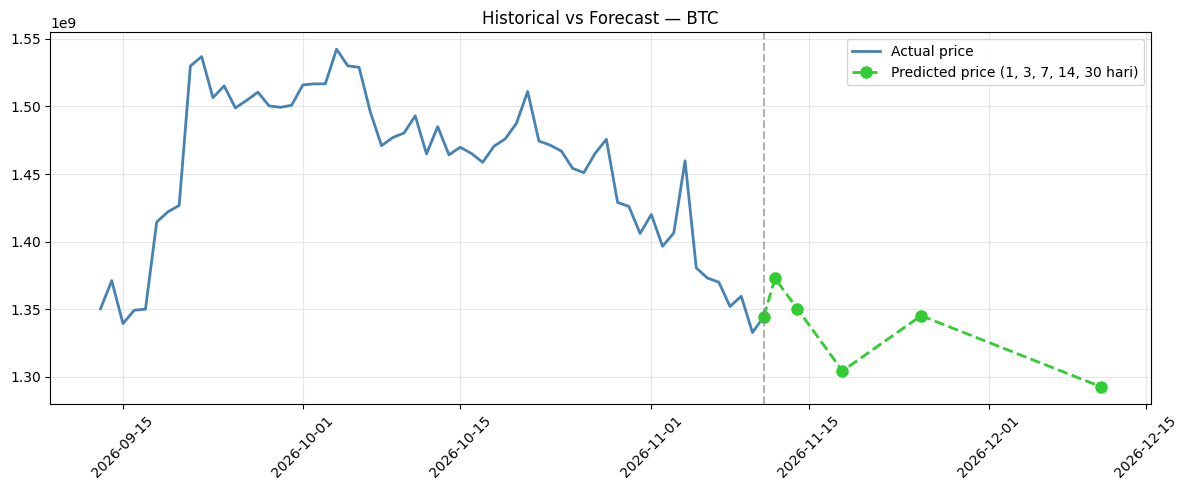

In [13]:
def plot_historical_vs_points(asset, future_df, n_historical_days=60):
    df_full = merged_data[asset].sort_values("Tanggal").reset_index(drop=True)
    historical = df_full[["Tanggal", "Close_indodax"]].tail(n_historical_days)

    last_date = df_full["Tanggal"].iloc[-1]
    last_close = df_full["Close_indodax"].iloc[-1]

    # Konversi future_df (string "Rp...") balik ke angka untuk diplot
    forecast_dates = [last_date] + [pd.to_datetime(d) for d in future_df["Tanggal Prediksi"]]
    forecast_prices = [last_close] + [
        float(p.replace("Rp", "").replace(",", "")) for p in future_df["Prediksi Harga"]
    ]

    plt.figure(figsize=(12, 5))
    plt.plot(historical["Tanggal"], historical["Close_indodax"],
              color="steelblue", linewidth=2, label="Actual price")
    plt.plot(forecast_dates, forecast_prices,
              color="limegreen", linewidth=2, linestyle="--", marker="o", markersize=8,
              label="Predicted price (1, 3, 7, 14, 30 hari)")

    plt.axvline(last_date, color="gray", linestyle="--", alpha=0.6)
    plt.title(f"Historical vs Forecast — {asset}")
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_historical_vs_points("BTC", future_btc)

In [14]:
eth_data = processed_data["ETH"]

lstm_models_eth = {}
lstm_target_scalers_eth = {}
lstm_runs_eth = []

for rep in range(len(SEEDS)):
    for h in HORIZONS:
        s = seed_for("ETH", "LSTM", h, rep)
        model, metrics, predictions, y_test, target_scaler = train_lstm_for_horizon(
            "ETH", eth_data, h, seed=s, save=(rep == 0))
        metrics.update({"asset": "ETH", "model": "LSTM", "rep": rep})
        lstm_runs_eth.append(metrics)
        print(f"  -> ETH LSTM h={h} rep={rep} MAPE={metrics['MAPE']:.2f}% epochs={metrics['epochs_run']}", flush=True)
        if rep == 0:
            lstm_models_eth[h] = model
            lstm_target_scalers_eth[h] = target_scaler

ALL_RUNS.extend(lstm_runs_eth)

metrics_df_eth = pd.DataFrame([m for m in lstm_runs_eth if m["rep"] == 0])
metrics_df_eth



=== Horizon 1 hari === seed=10
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_LSTM_h1_1500.keras, models/target_scaler_ETH_h1_1500.pkl
  -> ETH LSTM h=1 rep=0 MAPE=3.04% epochs=28

=== Horizon 3 hari === seed=11
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_LSTM_h3_1500.keras, models/target_scaler_ETH_h3_1500.pkl
  -> ETH LSTM h=3 rep=0 MAPE=3.90% epochs=66

=== Horizon 7 hari === seed=12
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_LSTM_h7_1500.keras, models/target_scaler_ETH_h7_1500.pkl
  -> ETH LSTM h=7 rep=0 MAPE=6.49% epochs=29

=== Horizon 14 hari === seed=13
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_LSTM_h14_1500.keras, models/target_scaler_ETH_h14_1500.pkl
  -> ETH LSTM h=14 rep=0 MAPE=10.67% epochs=27

=== Horizon 30 hari === seed=14
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/

,Horizon,h,MAE,RMSE,MAPE,R2,epochs_run,val_loss_best,seed,asset,model,rep
0,1d,1,1.107607e+06,1.624279e+06,3.038456,0.930755,28,0.048063,10,ETH,LSTM,0
1,3d,3,1.429645e+06,2.077729e+06,3.899742,0.887533,66,0.061722,11,ETH,LSTM,0
2,7d,7,2.404856e+06,3.242695e+06,6.494057,0.730285,29,0.078622,12,ETH,LSTM,0
3,14d,14,3.936009e+06,4.527624e+06,10.670347,0.488744,27,0.089830,13,ETH,LSTM,0
4,30d,30,5.083772e+06,6.154675e+06,13.911523,0.067058,19,0.096865,14,ETH,LSTM,0


In [15]:
future_eth = predict_future("ETH", lstm_models_eth, lstm_target_scalers_eth)
future_eth

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


,Horizon,Tanggal Prediksi,Harga Terakhir Diketahui,Prediksi Harga
0,1 hari,2026-11-12,"Rp37,333,000","Rp39,011,152"
1,3 hari,2026-11-14,"Rp37,333,000","Rp38,108,600"
2,7 hari,2026-11-18,"Rp37,333,000","Rp39,145,432"
3,14 hari,2026-11-25,"Rp37,333,000","Rp40,302,236"
4,30 hari,2026-12-11,"Rp37,333,000","Rp40,282,821"


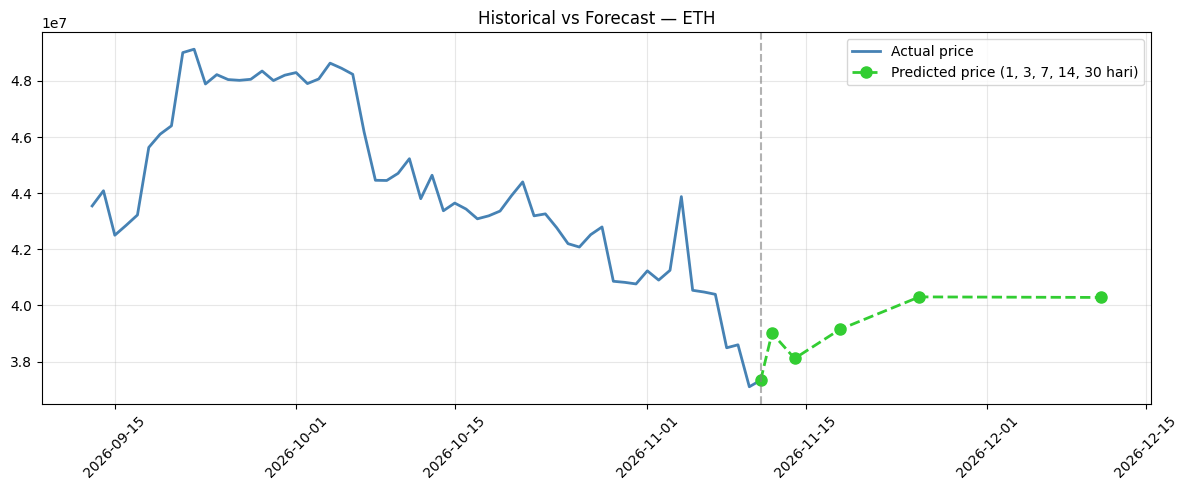

In [16]:
plot_historical_vs_points("ETH", future_eth)

In [17]:
sol_data = processed_data["SOL"]

lstm_models_sol = {}
lstm_target_scalers_sol = {}
lstm_runs_sol = []

for rep in range(len(SEEDS)):
    for h in HORIZONS:
        s = seed_for("SOL", "LSTM", h, rep)
        model, metrics, predictions, y_test, target_scaler = train_lstm_for_horizon(
            "SOL", sol_data, h, seed=s, save=(rep == 0))
        metrics.update({"asset": "SOL", "model": "LSTM", "rep": rep})
        lstm_runs_sol.append(metrics)
        print(f"  -> SOL LSTM h={h} rep={rep} MAPE={metrics['MAPE']:.2f}% epochs={metrics['epochs_run']}", flush=True)
        if rep == 0:
            lstm_models_sol[h] = model
            lstm_target_scalers_sol[h] = target_scaler

ALL_RUNS.extend(lstm_runs_sol)

metrics_df_sol = pd.DataFrame([m for m in lstm_runs_sol if m["rep"] == 0])
metrics_df_sol



=== Horizon 1 hari === seed=20
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_LSTM_h1_1500.keras, models/target_scaler_SOL_h1_1500.pkl
  -> SOL LSTM h=1 rep=0 MAPE=5.38% epochs=17

=== Horizon 3 hari === seed=21
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_LSTM_h3_1500.keras, models/target_scaler_SOL_h3_1500.pkl
  -> SOL LSTM h=3 rep=0 MAPE=7.15% epochs=35

=== Horizon 7 hari === seed=22
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_LSTM_h7_1500.keras, models/target_scaler_SOL_h7_1500.pkl
  -> SOL LSTM h=7 rep=0 MAPE=8.85% epochs=39

=== Horizon 14 hari === seed=23
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_LSTM_h14_1500.keras, models/target_scaler_SOL_h14_1500.pkl
  -> SOL LSTM h=14 rep=0 MAPE=10.95% epochs=17

=== Horizon 30 hari === seed=24
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/

,Horizon,h,MAE,RMSE,MAPE,R2,epochs_run,val_loss_best,seed,asset,model,rep
0,1d,1,87113.950617,119935.822798,5.383451,0.825822,17,0.040569,20,SOL,LSTM,0
1,3d,3,106180.474537,126333.641467,7.153368,0.809519,35,0.037241,21,SOL,LSTM,0
2,7d,7,135059.358796,164016.866901,8.854262,0.687128,39,0.048447,22,SOL,LSTM,0
3,14d,14,175140.635031,219789.984199,10.950770,0.460480,17,0.057962,23,SOL,LSTM,0
4,30d,30,280699.657407,322987.161738,19.372483,-0.163856,20,0.071955,24,SOL,LSTM,0


In [18]:
future_sol = predict_future("SOL", lstm_models_sol, lstm_target_scalers_sol)
future_sol

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


,Horizon,Tanggal Prediksi,Harga Terakhir Diketahui,Prediksi Harga
0,1 hari,2026-11-12,"Rp1,514,959","Rp1,598,002"
1,3 hari,2026-11-14,"Rp1,514,959","Rp1,649,908"
2,7 hari,2026-11-18,"Rp1,514,959","Rp1,632,556"
3,14 hari,2026-11-25,"Rp1,514,959","Rp1,665,286"
4,30 hari,2026-12-11,"Rp1,514,959","Rp1,855,474"


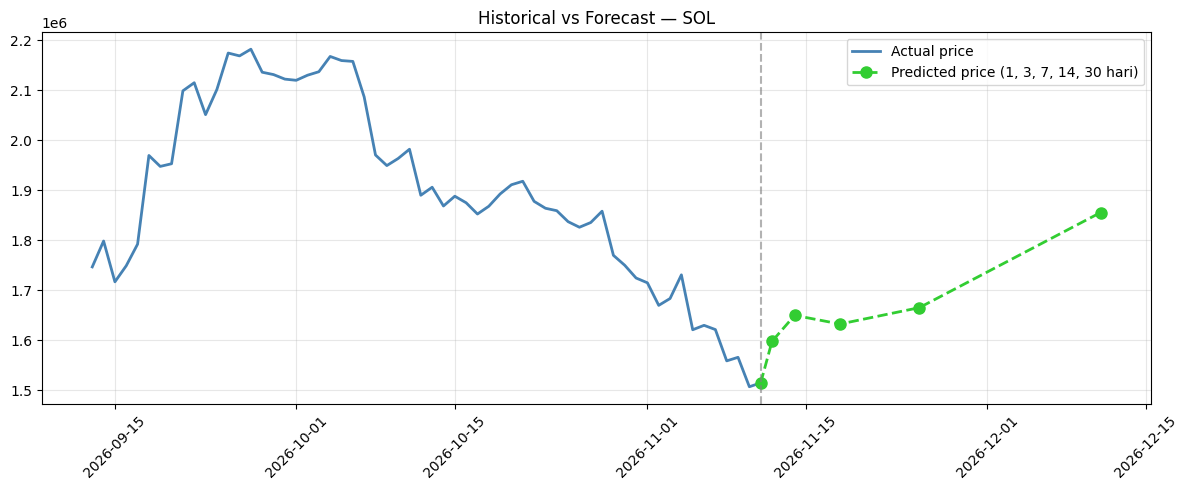

In [19]:
plot_historical_vs_points("SOL", future_sol)

In [20]:
def residual_block(x, filters, kernel_size, dilation_rate):
    """Satu blok TCN: dilated causal convolution + residual connection."""
    prev_x = x

    conv = Conv1D(filters, kernel_size, padding="causal",
                  dilation_rate=dilation_rate, activation="relu")(x)
    conv = Dropout(0.2)(conv)
    conv = Conv1D(filters, kernel_size, padding="causal",
                  dilation_rate=dilation_rate, activation="relu")(conv)

    if prev_x.shape[-1] != filters:
        prev_x = Conv1D(filters, 1, padding="same")(prev_x)

    res = Add()([prev_x, conv])
    res = Activation("relu")(res)
    return res

def build_tcn_model(window_size, n_features, filters=64, kernel_size=3, dilations=(1, 2, 4, 8)):
    inputs = Input(shape=(window_size, n_features))

    x = inputs
    for d in dilations:
        x = residual_block(x, filters, kernel_size, dilation_rate=d)

    x = Lambda(lambda t: t[:, -1, :])(x)
    x = Dense(32, activation="relu")(x)
    outputs = Dense(1)(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.001), loss="mae")
    return model

In [21]:
from tensorflow.keras.layers import Lambda

def train_tcn_for_horizon(asset, asset_data, horizon, seed=None, save=True,
                          feature_cols=FEATURE_COLS, window_size=WINDOW_SIZE):
    """Latih satu model TCN untuk satu horizon tertentu, kembalikan model + metrik evaluasi."""
    target_col = f"Target_{horizon}d"

    # Pipeline TCN identik dengan LSTM; yang berbeda hanya arsitektur dan nama file.
    X_train, y_train = create_sequences(asset_data["train"], feature_cols, target_col, window_size)
    X_val, y_val = create_sequences(asset_data["val"], feature_cols, target_col, window_size)
    X_test, y_test = create_sequences(asset_data["test"], feature_cols, target_col, window_size)

    target_scaler = MinMaxScaler(feature_range=(0, 1))
    y_train_scaled = target_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
    y_val_scaled = target_scaler.transform(y_val.reshape(-1, 1)).flatten()

    print(f"\n=== [TCN] Horizon {horizon} hari === seed={seed}")
    print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

    if seed is not None:
        set_seed(seed)

    model = build_tcn_model(window_size, n_features=len(feature_cols))
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    lr_scheduler = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=0)

    hist = model.fit(
        X_train, y_train_scaled,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val_scaled),
        callbacks=[early_stop, lr_scheduler], verbose=0,
    )

    predictions_scaled = model.predict(X_test, verbose=0).flatten()
    predictions = target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()

    _dates = pd.to_datetime(asset_data["test"]["Tanggal"]).iloc[window_size - 1:].reset_index(drop=True)
    PRED_RECORDS.append(pd.DataFrame({
        "asset": asset, "model": "TCN", "h": horizon, "seed": seed,
        "date": _dates.values[:len(predictions)],
        "y_true": y_test, "y_pred": predictions,
    }))

    metrics = {
        "Horizon": f"{horizon}d",
        "h": horizon,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAPE": mean_absolute_percentage_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
        "epochs_run": len(hist.history["loss"]),
        "val_loss_best": float(np.min(hist.history["val_loss"])),
        "seed": seed,
    }

    if save:
        model_path = os.path.join(SCALER_DIR, f"{asset}_TCN_h{horizon}_1500.keras")
        model.save(model_path)

        # TCN memakai prefix target_scaler_TCN_.
        target_scaler_path = os.path.join(SCALER_DIR, f"target_scaler_TCN_{asset}_h{horizon}_1500.pkl")
        joblib.dump(target_scaler, target_scaler_path)

        print(f"Tersimpan: {model_path}, {target_scaler_path}")
    else:
        print("Model tidak disimpan (rep > 0), supaya file kanonik tidak tertimpa.")

    return model, metrics, predictions, y_test, target_scaler


In [22]:
model = build_tcn_model(WINDOW_SIZE, len(FEATURE_COLS))
model.summary()

Model: "functional_46"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_46      │ (None, 60, 10)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 60, 64)    │      1,984 │ input_layer_46[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_92          │ (None, 60, 64)    │          0 │ conv1d[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 60, 64)    │        704 │ input_layer_46[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 60, 64)    │     12,352 │ dropout_92[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 60, 64)    │          0 │ conv1d_2[0][0],   │
│                     │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 60, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 60, 64)    │     12,352 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_93          │ (None, 60, 64)    │          0 │ conv1d_3[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 60, 64)    │     12,352 │ dropout_93[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 60, 64)    │          0 │ activation[0][0], │
│                     │                   │            │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 60, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 60, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_94          │ (None, 60, 64)    │          0 │ conv1d_5[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 60, 64)    │     12,352 │ dropout_94[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 60, 64)    │          0 │ activation_1[0][… │
│                     │                   │            │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 60, 64)    │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 60, 64)    │     12,352 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_95          │ (None, 60, 64)    │          0 │ conv1d_7[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 91,265 (356.50 KB)

 Trainable params: 91,265 (356.50 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
tcn_models = {}
tcn_target_scalers = {}
tcn_runs = []

for rep in range(len(SEEDS)):
    for h in HORIZONS:
        s = seed_for("BTC", "TCN", h, rep)
        model, metrics, predictions, y_test, target_scaler = train_tcn_for_horizon(
            "BTC", btc_data, h, seed=s, save=(rep == 0))
        metrics.update({"asset": "BTC", "model": "TCN", "rep": rep})
        tcn_runs.append(metrics)
        print(f"  -> BTC TCN h={h} rep={rep} MAPE={metrics['MAPE']:.2f}% epochs={metrics['epochs_run']}", flush=True)
        if rep == 0:
            tcn_models[h] = model
            tcn_target_scalers[h] = target_scaler

ALL_RUNS.extend(tcn_runs)

metrics_df_tcn = pd.DataFrame([m for m in tcn_runs if m["rep"] == 0])
metrics_df_tcn



=== [TCN] Horizon 1 hari === seed=100
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_TCN_h1_1500.keras, models/target_scaler_TCN_BTC_h1_1500.pkl
  -> BTC TCN h=1 rep=0 MAPE=1.43% epochs=33

=== [TCN] Horizon 3 hari === seed=101
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_TCN_h3_1500.keras, models/target_scaler_TCN_BTC_h3_1500.pkl
  -> BTC TCN h=3 rep=0 MAPE=2.37% epochs=70

=== [TCN] Horizon 7 hari === seed=102
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_TCN_h7_1500.keras, models/target_scaler_TCN_BTC_h7_1500.pkl
  -> BTC TCN h=7 rep=0 MAPE=4.08% epochs=22

=== [TCN] Horizon 14 hari === seed=103
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/BTC_TCN_h14_1500.keras, models/target_scaler_TCN_BTC_h14_1500.pkl
  -> BTC TCN h=14 rep=0 MAPE=6.31% epochs=40

=== [TCN] Horizon 30 hari === seed=104
Train: (970, 60, 10) | Val: (161, 60, 10

,Horizon,h,MAE,RMSE,MAPE,R2,epochs_run,val_loss_best,seed,asset,model,rep
0,1d,1,1.815251e+07,2.635937e+07,1.432179,0.966839,33,0.016756,100,BTC,TCN,0
1,3d,3,3.014104e+07,4.577111e+07,2.370159,0.901050,70,0.029922,101,BTC,TCN,0
2,7d,7,5.278142e+07,7.988010e+07,4.082540,0.705813,22,0.044438,102,BTC,TCN,0
3,14d,14,8.069261e+07,1.059036e+08,6.312080,0.506631,40,0.064234,103,BTC,TCN,0
4,30d,30,1.484793e+08,1.759337e+08,11.260738,-0.299076,16,0.084162,104,BTC,TCN,0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


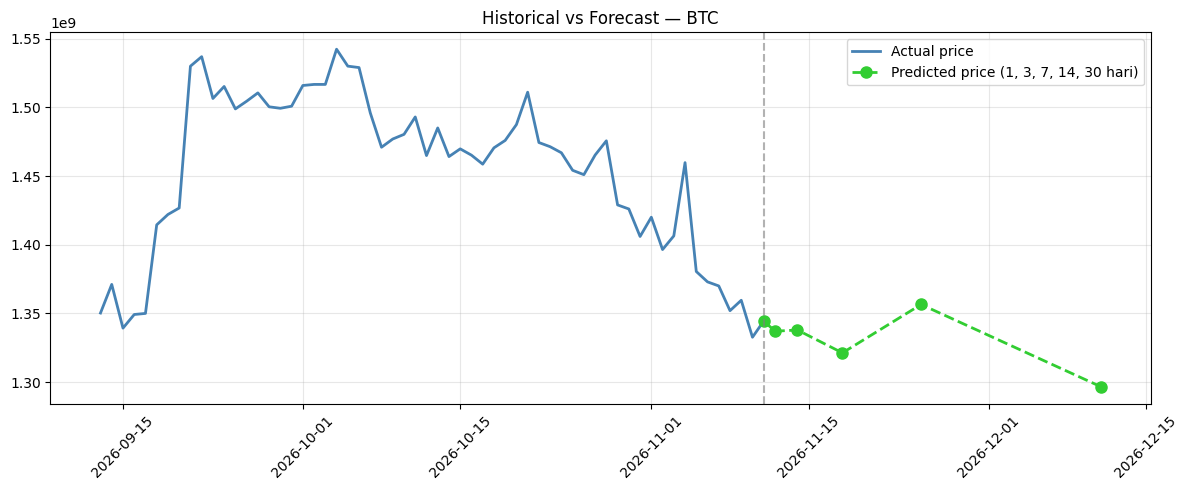

In [24]:
future_btc_tcn = predict_future("BTC", tcn_models, tcn_target_scalers)
plot_historical_vs_points("BTC", future_btc_tcn)

In [25]:
tcn_models_eth, tcn_target_scalers_eth, tcn_runs_eth = {}, {}, []

for rep in range(len(SEEDS)):
    for h in HORIZONS:
        s = seed_for("ETH", "TCN", h, rep)
        model, metrics, predictions, y_test, target_scaler = train_tcn_for_horizon(
            "ETH", eth_data, h, seed=s, save=(rep == 0))
        metrics.update({"asset": "ETH", "model": "TCN", "rep": rep})
        tcn_runs_eth.append(metrics)
        print(f"  -> ETH TCN h={h} rep={rep} MAPE={metrics['MAPE']:.2f}% epochs={metrics['epochs_run']}", flush=True)
        if rep == 0:
            tcn_models_eth[h] = model
            tcn_target_scalers_eth[h] = target_scaler

ALL_RUNS.extend(tcn_runs_eth)

metrics_df_tcn_eth = pd.DataFrame([m for m in tcn_runs_eth if m["rep"] == 0])
metrics_df_tcn_eth



=== [TCN] Horizon 1 hari === seed=110
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_TCN_h1_1500.keras, models/target_scaler_TCN_ETH_h1_1500.pkl
  -> ETH TCN h=1 rep=0 MAPE=1.77% epochs=45

=== [TCN] Horizon 3 hari === seed=111
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_TCN_h3_1500.keras, models/target_scaler_TCN_ETH_h3_1500.pkl
  -> ETH TCN h=3 rep=0 MAPE=3.17% epochs=28

=== [TCN] Horizon 7 hari === seed=112
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_TCN_h7_1500.keras, models/target_scaler_TCN_ETH_h7_1500.pkl
  -> ETH TCN h=7 rep=0 MAPE=5.48% epochs=21

=== [TCN] Horizon 14 hari === seed=113
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/ETH_TCN_h14_1500.keras, models/target_scaler_TCN_ETH_h14_1500.pkl
  -> ETH TCN h=14 rep=0 MAPE=8.41% epochs=17

=== [TCN] Horizon 30 hari === seed=114
Train: (970, 60, 10) | Val: (161, 60, 10

,Horizon,h,MAE,RMSE,MAPE,R2,epochs_run,val_loss_best,seed,asset,model,rep
0,1d,1,6.509395e+05,9.743220e+05,1.765011,0.975084,45,0.029639,110,ETH,TCN,0
1,3d,3,1.174757e+06,1.832595e+06,3.167991,0.912506,28,0.055673,111,ETH,TCN,0
2,7d,7,2.055247e+06,2.992502e+06,5.484759,0.770300,21,0.078673,112,ETH,TCN,0
3,14d,14,3.301478e+06,4.564690e+06,8.414327,0.480339,17,0.087346,113,ETH,TCN,0
4,30d,30,5.073357e+06,5.971331e+06,13.474365,0.121814,16,0.114079,114,ETH,TCN,0


In [26]:
tcn_models_sol, tcn_target_scalers_sol, tcn_runs_sol = {}, {}, []

for rep in range(len(SEEDS)):
    for h in HORIZONS:
        s = seed_for("SOL", "TCN", h, rep)
        model, metrics, predictions, y_test, target_scaler = train_tcn_for_horizon(
            "SOL", sol_data, h, seed=s, save=(rep == 0))
        metrics.update({"asset": "SOL", "model": "TCN", "rep": rep})
        tcn_runs_sol.append(metrics)
        print(f"  -> SOL TCN h={h} rep={rep} MAPE={metrics['MAPE']:.2f}% epochs={metrics['epochs_run']}", flush=True)
        if rep == 0:
            tcn_models_sol[h] = model
            tcn_target_scalers_sol[h] = target_scaler

ALL_RUNS.extend(tcn_runs_sol)

metrics_df_tcn_sol = pd.DataFrame([m for m in tcn_runs_sol if m["rep"] == 0])
metrics_df_tcn_sol



=== [TCN] Horizon 1 hari === seed=120
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_TCN_h1_1500.keras, models/target_scaler_TCN_SOL_h1_1500.pkl
  -> SOL TCN h=1 rep=0 MAPE=2.25% epochs=46

=== [TCN] Horizon 3 hari === seed=121
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_TCN_h3_1500.keras, models/target_scaler_TCN_SOL_h3_1500.pkl
  -> SOL TCN h=3 rep=0 MAPE=4.54% epochs=30

=== [TCN] Horizon 7 hari === seed=122
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_TCN_h7_1500.keras, models/target_scaler_TCN_SOL_h7_1500.pkl
  -> SOL TCN h=7 rep=0 MAPE=7.57% epochs=19

=== [TCN] Horizon 14 hari === seed=123
Train: (970, 60, 10) | Val: (161, 60, 10) | Test: (162, 60, 10)
Tersimpan: models/SOL_TCN_h14_1500.keras, models/target_scaler_TCN_SOL_h14_1500.pkl
  -> SOL TCN h=14 rep=0 MAPE=15.98% epochs=23

=== [TCN] Horizon 30 hari === seed=124
Train: (970, 60, 10) | Val: (161, 60, 1

,Horizon,h,MAE,RMSE,MAPE,R2,epochs_run,val_loss_best,seed,asset,model,rep
0,1d,1,35157.358796,48817.317345,2.254133,0.971144,46,0.017326,120,SOL,TCN,0
1,3d,3,69285.572531,88467.964127,4.542575,0.906592,30,0.030114,121,SOL,TCN,0
2,7d,7,116388.420525,144339.572725,7.565030,0.757696,19,0.040829,122,SOL,TCN,0
3,14d,14,236755.926698,266547.155024,15.975964,0.206513,23,0.061796,123,SOL,TCN,0
4,30d,30,239839.345679,273803.132604,15.044653,0.163616,18,0.060425,124,SOL,TCN,0


In [27]:
def compare_lstm_tcn(metrics_lstm_df, metrics_tcn_df, asset_name):
    comparison = metrics_lstm_df.merge(metrics_tcn_df, on="Horizon", suffixes=("_LSTM", "_TCN"))
    comparison.insert(0, "Aset", asset_name)
    return comparison

comparison_all = pd.concat([
    compare_lstm_tcn(metrics_df, metrics_df_tcn, "BTC"),
    compare_lstm_tcn(metrics_df_eth, metrics_df_tcn_eth, "ETH"),
    compare_lstm_tcn(metrics_df_sol, metrics_df_tcn_sol, "SOL"),
], ignore_index=True)

comparison_all

,Aset,Horizon,h_LSTM,MAE_LSTM,RMSE_LSTM,MAPE_LSTM,R2_LSTM,epochs_run_LSTM,val_loss_best_LSTM,seed_LSTM,...,MAE_TCN,RMSE_TCN,MAPE_TCN,R2_TCN,epochs_run_TCN,val_loss_best_TCN,seed_TCN,asset_TCN,model_TCN,rep_TCN
0,BTC,1d,1,4.268869e+07,6.197851e+07,3.305852,0.816665,18,0.035709,0,...,1.815251e+07,2.635937e+07,1.432179,0.966839,33,0.016756,100,BTC,TCN,0
1,BTC,3d,3,4.440827e+07,6.659147e+07,3.457784,0.790555,44,0.039983,1,...,3.014104e+07,4.577111e+07,2.370159,0.901050,70,0.029922,101,BTC,TCN,0
2,BTC,7d,7,1.040093e+08,1.292854e+08,7.828555,0.229371,17,0.076817,2,...,5.278142e+07,7.988010e+07,4.082540,0.705813,22,0.044438,102,BTC,TCN,0
3,BTC,14d,14,8.616891e+07,1.206477e+08,6.610032,0.359693,27,0.059639,3,...,8.069261e+07,1.059036e+08,6.312080,0.506631,40,0.064234,103,BTC,TCN,0
4,BTC,30d,30,1.458427e+08,1.722175e+08,11.016671,-0.244775,20,0.074922,4,...,1.484793e+08,1.759337e+08,11.260738,-0.299076,16,0.084162,104,BTC,TCN,0
5,ETH,1d,1,1.107607e+06,1.624279e+06,3.038456,0.930755,28,0.048063,10,...,6.509395e+05,9.743220e+05,1.765011,0.975084,45,0.029639,110,ETH,TCN,0
6,ETH,3d,3,1.429645e+06,2.077729e+06,3.899742,0.887533,66,0.061722,11,...,1.174757e+06,1.832595e+06,3.167991,0.912506,28,0.055673,111,ETH,TCN,0
7,ETH,7d,7,2.404856e+06,3.242695e+06,6.494057,0.730285,29,0.078622,12,...,2.055247e+06,2.992502e+06,5.484759,0.770300,21,0.078673,112,ETH,TCN,0
8,ETH,14d,14,3.936009e+06,4.527624e+06,10.670347,0.488744,27,0.089830,13,...,3.301478e+06,4.564690e+06,8.414327,0.480339,17,0.087346,113,ETH,TCN,0
9,ETH,30d,30,5.083772e+06,6.154675e+06,13.911523,0.067058,19,0.096865,14,...,5.073357e+06,5.971331e+06,13.474365,0.121814,16,0.114079,114,ETH,TCN,0


In [28]:
def get_expected_returns(horizon, future_dict, last_prices, assets=["BTC", "ETH", "SOL"]):
    """Konversi harga prediksi -> return, untuk satu horizon, seluruh aset."""
    # mu = (pred - last) / last = return total h hari, BUKAN annualized.
    mu = []
    for asset in assets:
        future_df = future_dict[asset]
        row = future_df[future_df["Horizon"] == f"{horizon} hari"].iloc[0]
        # Harga diambil dari string "Rp..." hasil predict_future
        pred_price = float(row["Prediksi Harga"].replace("Rp", "").replace(",", ""))
        last_price = last_prices[asset]
        r = (pred_price - last_price) / last_price
        mu.append(r)
    return np.array(mu)

In [29]:
def get_covariance_matrix(horizon, assets=["BTC", "ETH", "SOL"], lookback_days=90):
    """Hitung matriks covariance dari return historis harian, diskalakan ke horizon h hari."""
    # 90 return harian; np.cov memakai ddof=1 (pembagi n-1 = 89).
    returns = {}
    for asset in assets:
        df = merged_data[asset].sort_values("Tanggal").tail(lookback_days + 1)
        daily_returns = df["Close_indodax"].pct_change().dropna()
        returns[asset] = daily_returns.values[-lookback_days:]

    returns_matrix = np.array([returns[a] for a in assets])
    cov_daily = np.cov(returns_matrix)
    # Sigma_h = Sigma_harian x h. Sigma sama untuk LSTM & TCN (hanya memakai Close_indodax).
    cov_h = cov_daily * horizon  # asumsi return harian independen, diskalakan linear ke horizon
    return cov_h

In [30]:
from scipy.optimize import minimize

# BI Rate dari Bank Indonesia
BI_RATE_ANNUAL = 0.0575 
RF_DAILY = BI_RATE_ANNUAL / 365

def optimize_markowitz(mu, cov, rf, assets=["BTC", "ETH", "SOL"], min_weight=0.2):
    """Optimasi bobot portofolio: maksimalkan Sharpe Ratio, dengan Σw=1 dan w>=min_weight."""
    n = len(mu)

    def neg_sharpe(w):
        port_return = w @ mu
        port_std = np.sqrt(w @ cov @ w)
        return -(port_return - rf) / port_std

    constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
    # Cek sum(w)=1 dan tiap w >= min_weight. Batas atas efektif 3 aset = 1 - 2*min_weight;
    # min_weight > 1/3 membuat kendala tidak feasible.
    bounds = [(min_weight, 1) for _ in range(n)] 
    w0 = np.array([1 / n] * n)

    result = minimize(neg_sharpe, w0, method="SLSQP", bounds=bounds, constraints=constraints)
    weights = result.x
    port_return = weights @ mu
    port_std = np.sqrt(weights @ cov @ weights)
    sharpe = (port_return - rf) / port_std

    return {
        "weights": dict(zip(assets, weights)),
        "expected_return": port_return,
        "risk": port_std,
        "sharpe_ratio": sharpe,
    }

In [31]:
last_prices = {
    "BTC": merged_data["BTC"]["Close_indodax"].iloc[-1],
    "ETH": merged_data["ETH"]["Close_indodax"].iloc[-1],
    "SOL": merged_data["SOL"]["Close_indodax"].iloc[-1],
}
# future_dict memakai prediksi LSTM. Untuk Markowitz TCN, ganti ke future_btc_tcn/future_eth_tcn/future_sol_tcn.
future_dict = {"BTC": future_btc, "ETH": future_eth, "SOL": future_sol}

markowitz_results = []
# Urutan mu harus sama dengan urutan aset pada cov: BTC, ETH, SOL.
for h in HORIZONS:
    mu = get_expected_returns(h, future_dict, last_prices)
    cov = get_covariance_matrix(h)
    # rf_h diskalakan ke horizon; jangan pakai RF_DAILY langsung.
    rf_h = RF_DAILY * h

    result = optimize_markowitz(mu, cov, rf_h)
    markowitz_results.append({
        "Horizon": f"{h}d",
        "Bobot_BTC": f"{result['weights']['BTC']:.1%}",
        "Bobot_ETH": f"{result['weights']['ETH']:.1%}",
        "Bobot_SOL": f"{result['weights']['SOL']:.1%}",
        "Expected_Return": f"{result['expected_return']:.2%}",
        "Risk": f"{result['risk']:.2%}",
        "Sharpe_Ratio": f"{result['sharpe_ratio']:.3f}",
    })

markowitz_df = pd.DataFrame(markowitz_results)
markowitz_df

,Horizon,Bobot_BTC,Bobot_ETH,Bobot_SOL,Expected_Return,Risk,Sharpe_Ratio
0,1d,20.0%,20.0%,60.0%,4.61%,2.62%,1.756
1,3d,20.0%,20.0%,60.0%,5.84%,4.53%,1.280
2,7d,20.0%,20.0%,60.0%,5.03%,6.92%,0.711
3,14d,20.0%,20.0%,60.0%,7.55%,9.79%,0.749
4,30d,20.0%,20.0%,60.0%,14.29%,14.33%,0.965


In [32]:
# Nilai mu ini bisa dibandingkan dengan analysis[h].mu di predictions.json.
expected_returns_table = []

for h in HORIZONS:
    mu = get_expected_returns(h, future_dict, last_prices)
    expected_returns_table.append({
        "Horizon": f"{h}d",
        "Expected_Return_BTC": f"{mu[0]:.2%}",
        "Expected_Return_ETH": f"{mu[1]:.2%}",
        "Expected_Return_SOL": f"{mu[2]:.2%}",
    })

expected_returns_df = pd.DataFrame(expected_returns_table)
expected_returns_df

,Horizon,Expected_Return_BTC,Expected_Return_ETH,Expected_Return_SOL
0,1d,2.10%,4.50%,5.48%
1,3d,0.42%,2.08%,8.91%
2,7d,-2.99%,4.85%,7.76%
3,14d,0.05%,7.95%,9.92%
4,30d,-3.86%,7.90%,22.48%


In [33]:
# ================= RINGKASAN MULTI-SEED (mean +- std, persistence, MASE) =================
runs = pd.DataFrame(ALL_RUNS)

def persistence_stats(asset, h):
    """MAE & MAPE naive (harga t+h = harga t), pada TITIK yang sama dengan model.

    Model dievaluasi pada baris WINDOW_SIZE-1 .. akhir test, jadi persistence
    juga dibatasi ke tanggal itu (bukan seluruh isi split test).
    """
    df = merged_data[asset].sort_values("Tanggal").reset_index(drop=True)
    close = df.set_index("Tanggal")["Close_indodax"]
    future = close.shift(-h)

    dates = pd.to_datetime(processed_data[asset]["test"]["Tanggal"]).iloc[WINDOW_SIZE - 1:]
    y_true = future.reindex(dates).values
    y_naive = close.reindex(dates).values

    mask = ~np.isnan(y_true)
    y_true, y_naive = y_true[mask], y_naive[mask]

    mae = float(np.abs(y_true - y_naive).mean())
    mape = float((np.abs(y_true - y_naive) / y_true).mean() * 100)
    return mae, mape

summary = (runs.groupby(["asset", "model", "h"])
           .agg(MAPE_mean=("MAPE", "mean"), MAPE_std=("MAPE", "std"),
                MAE_mean=("MAE", "mean"), R2_mean=("R2", "mean"),
                epochs_mean=("epochs_run", "mean"), n=("MAPE", "size"))
           .reset_index())

_pers = [persistence_stats(a, h) for a, h in zip(summary["asset"], summary["h"])]
summary["pers_MAE"] = [p[0] for p in _pers]
summary["pers_MAPE"] = [p[1] for p in _pers]
summary["ratio_MAPE"] = summary["MAPE_mean"] / summary["pers_MAPE"]
summary["MASE"] = summary["MAE_mean"] / summary["pers_MAE"]   # < 1 = mengalahkan naive
summary["skill"] = 1 - summary["MASE"]
summary["dataset_rows"] = len(merged_data[ASSETS[0]])   # 1500 di v3, 1000 di v2

print("Jumlah seed per sel (harus = len(SEEDS)):")
print(summary["n"].value_counts().to_string())

print("\n=== MASE (< 1 = mengalahkan naive), LSTM ===")
print(summary[summary.model == "LSTM"].pivot(index="h", columns="asset", values="MASE").round(3).to_string())

print("\n=== MASE (< 1 = mengalahkan naive), TCN ===")
print(summary[summary.model == "TCN"].pivot(index="h", columns="asset", values="MASE").round(3).to_string())

print("\n=== SELESAI: sel yang mengalahkan naive:",
      int((summary["MASE"] < 1).sum()), "/", len(summary), "===")

runs.to_csv("results_seeds_1500.csv", index=False)
summary.to_csv("results_summary_1500.csv", index=False)
print("Tersimpan: results_seeds_1500.csv (semua seed) & results_summary_1500.csv (mean +- std)")

# Ekspor prediksi per titik: bahan perbandingan v3 (1500) vs v2 (1000).
# Jendela v2 (87 titik, 2026-07-18..2026-10-12) adalah SUBSET jendela v3 (162 titik),
# jadi MASE kedua versi bisa dibandingkan pada tanggal yang identik.
pred_df = pd.concat(PRED_RECORDS, ignore_index=True)
pred_df.to_csv("predictions_all_1500.csv", index=False)
print("Tersimpan: predictions_all_1500.csv (%d baris | %d titik per sel)"
      % (len(pred_df), pred_df.groupby(["asset", "model", "h", "seed"]).size().max()))

summary


Jumlah seed per sel (harus = len(SEEDS)):
n
3    30

=== MASE (< 1 = mengalahkan naive), LSTM ===
asset    BTC    ETH    SOL
h                         
1      2.374  1.994  2.546
3      1.624  1.358  1.744
7      1.514  1.250  1.293
14     1.131  1.148  1.194
30     1.049  0.924  1.030

=== MASE (< 1 = mengalahkan naive), TCN ===
asset    BTC    ETH    SOL
h                         
1      1.164  1.029  1.084
3      1.037  1.039  1.162
7      1.034  1.048  1.322
14     1.047  1.002  1.455
30     1.287  0.881  0.930

=== SELESAI: sel yang mengalahkan naive: 3 / 30 ===
Tersimpan: results_seeds_1500.csv (semua seed) & results_summary_1500.csv (mean +- std)
Tersimpan: predictions_all_1500.csv (14580 baris | 162 titik per sel)


,asset,model,h,MAPE_mean,MAPE_std,MAE_mean,R2_mean,epochs_mean,n,pers_MAE,pers_MAPE,ratio_MAPE,MASE,skill,dataset_rows
0,BTC,LSTM,1,2.910821,0.392730,3.740788e+07,0.854185,34.666667,3,1.575628e+07,1.238221,2.350810,2.374157,-1.374157,1500
1,BTC,LSTM,3,3.687695,0.389359,4.695456e+07,0.782400,31.666667,3,2.891204e+07,2.266529,1.627023,1.624049,-0.624049,1500
2,BTC,LSTM,7,5.736840,1.814327,7.532955e+07,0.494986,25.000000,3,4.976708e+07,3.887843,1.475584,1.513642,-0.513642,1500
3,BTC,LSTM,14,6.571556,0.033817,8.542798e+07,0.395755,28.333333,3,7.550227e+07,5.856841,1.122031,1.131462,-0.131462,1500
4,BTC,LSTM,30,10.343768,0.591742,1.357021e+08,-0.101929,24.666667,3,1.293178e+08,10.097899,1.024349,1.049369,-0.049369,1500
5,BTC,TCN,1,1.447694,0.017027,1.833990e+07,0.966462,47.000000,3,1.575628e+07,1.238221,1.169173,1.163974,-0.163974,1500
6,BTC,TCN,3,2.346041,0.025791,2.996763e+07,0.900175,46.000000,3,2.891204e+07,2.266529,1.035081,1.036510,-0.036510,1500
7,BTC,TCN,7,3.997469,0.075458,5.148149e+07,0.718456,31.666667,3,4.976708e+07,3.887843,1.028197,1.034449,-0.034449,1500
8,BTC,TCN,14,6.103096,0.252385,7.908078e+07,0.466565,26.666667,3,7.550227e+07,5.856841,1.042046,1.047396,-0.047396,1500
9,BTC,TCN,30,12.498698,1.191966,1.664491e+08,-0.624339,16.333333,3,1.293178e+08,10.097899,1.237752,1.287132,-0.287132,1500
